<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp20_Future_Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 20: Future Sales Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement Future Sales Prediction using a suitable machine learning algorithm.

## Background
Companies spend on advertising through several channels (**TV, Radio, Newspaper**) and want to forecast **future sales** for planned budgets. This is a *regression* problem. We compare Linear Regression (with and without a TV x Radio interaction), Random Forest and Gradient Boosting, then use the best model to predict sales for **future budget scenarios** and to find the best way to split a fixed budget.



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We generate **300 past campaigns** (budgets in thousands of dollars, sales in thousands of units) modelled on the well-known *Advertising* dataset: TV and Radio drive sales (with a synergy when used together), Newspaper has almost no effect. Saved as `advertising.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 300
tv = rng.uniform(0, 300, n).round(1)
radio = rng.uniform(0, 50, n).round(1)
newspaper = rng.uniform(0, 100, n).round(1)
sales = (3 + 0.045 * tv + 0.19 * radio + 0.002 * newspaper + 0.0011 * tv * radio + rng.normal(0, 1.3, n)).round(1)

pd.DataFrame({"TV": tv, "Radio": radio, "Newspaper": newspaper, "Sales": sales}).to_csv("advertising.csv", index=False)
print("Saved advertising.csv")

Saved advertising.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("advertising.csv")
df.head()

,TV,Radio,Newspaper,Sales
0,112.4,2.6,16.9,9.3
1,285.2,26.6,27.9,27.7
2,219.6,27.0,17.7,25.8
3,179.6,31.9,8.9,23.2
4,46.8,36.3,12.1,13.2


## Step 3: Data Preprocessing
Check for missing values and duplicates and split into train/test sets. (All features are on comparable ranges and tree/linear models are used inside pipelines, so only basic cleaning is needed.)

In [4]:
from sklearn.model_selection import train_test_split

print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Missing values: 0 | Duplicates: 0
Train: (240, 3) Test: (60, 3)


## Step 4: Exploratory Data Analysis (EDA)

           count    mean    std  min    25%     50%     75%    max
TV         300.0  148.56  88.30  1.5  71.75  153.50  227.08  297.0
Radio      300.0   25.54  15.13  0.5  12.48   26.10   38.65   50.0
Newspaper  300.0   47.11  28.34  0.5  20.98   45.25   71.70   99.7
Sales      300.0   18.75   8.06  3.0  12.78   17.85   24.72   40.9

Correlation with Sales:
 TV           0.715
Radio        0.580
Newspaper    0.016
Name: Sales, dtype: float64


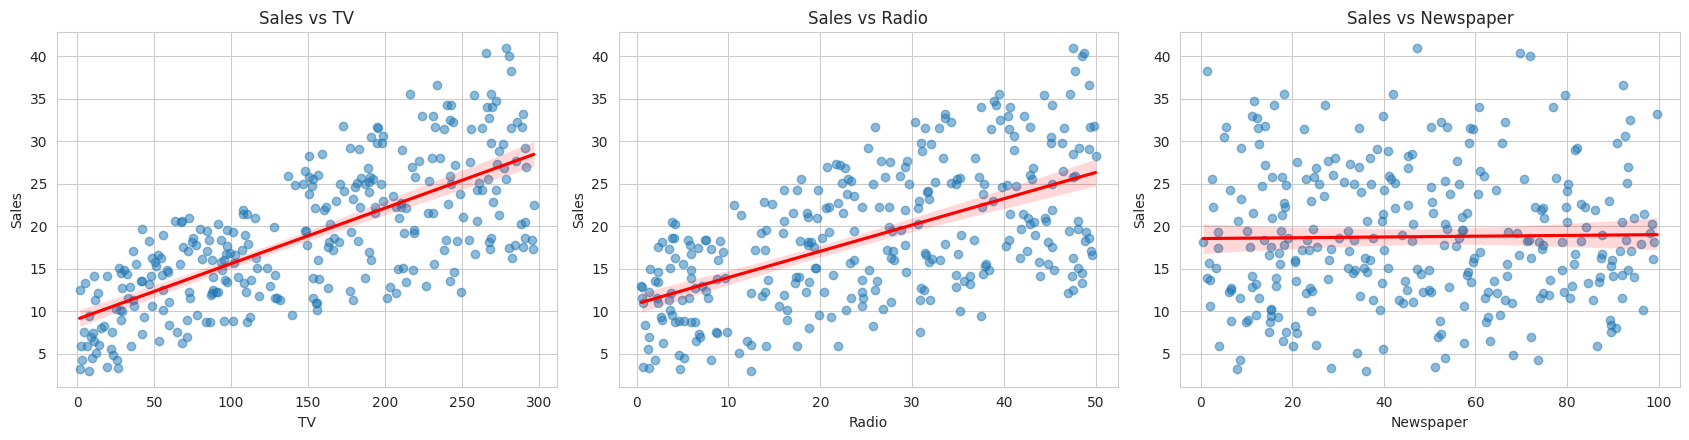

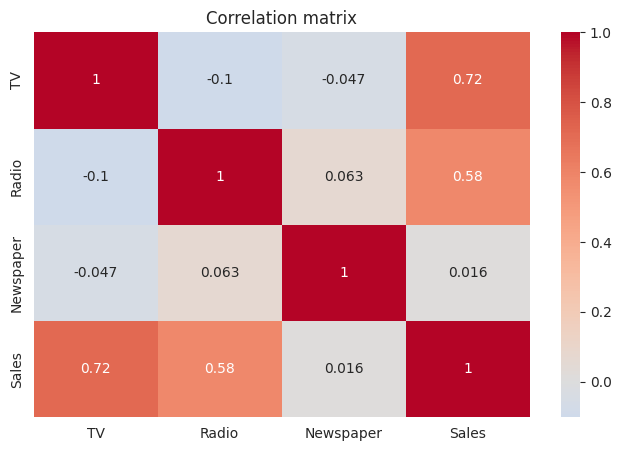

In [5]:
print(df.describe().T.round(2))
print("\nCorrelation with Sales:\n", df.corr()["Sales"].drop("Sales").round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax, scatter_kws={"alpha": .5}, line_kws={"color": "red"})
    ax.set_title(f"Sales vs {col}")
plt.tight_layout(); plt.show()

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", center=0); plt.title("Correlation matrix"); plt.show()

## Step 5: Model Training
Train four models. The 'Linear + interaction' model adds the `TV x Radio` product term, because the two channels reinforce each other.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Linear + interaction": make_pipeline(PolynomialFeatures(2, interaction_only=True, include_bias=False), StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
}
for m in models.values():
    m.fit(X_train, y_train)
print("Trained:", list(models))

Trained: ['Linear Regression', 'Linear + interaction', 'Random Forest', 'Gradient Boosting']


## Step 6: Model Evaluation
Compare MAE, RMSE, R-squared and 5-fold CV R-squared, then plot predictions and residuals of the best model.

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, p), "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "R2": r2_score(y_test, p), "CV R2": cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()})
results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("CV R2", ascending=False)
print(results)
best_name = results.index[0]
best = models[best_name]
print("\nBest model (by CV R2):", best_name)

                        MAE   RMSE     R2  CV R2
Model                                           
Linear + interaction  1.150  1.405  0.965  0.977
Random Forest         1.345  1.623  0.953  0.961
Gradient Boosting     1.237  1.514  0.959  0.958
Linear Regression     1.498  1.929  0.933  0.939

Best model (by CV R2): Linear + interaction


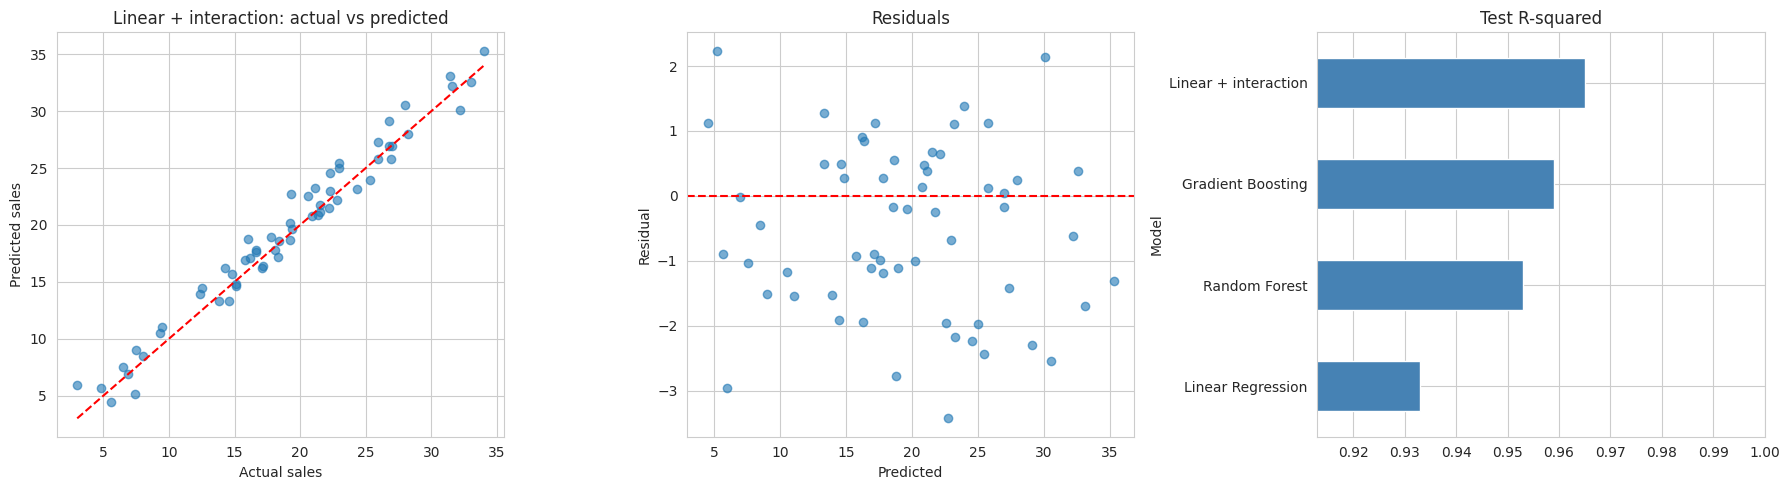

In [8]:
p = best.predict(X_test)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, p, alpha=.6); lim = [y_test.min(), y_test.max()]; axes[0].plot(lim, lim, "r--")
axes[0].set_xlabel("Actual sales"); axes[0].set_ylabel("Predicted sales"); axes[0].set_title(f"{best_name}: actual vs predicted")
axes[1].scatter(p, y_test - p, alpha=.6); axes[1].axhline(0, color="r", linestyle="--"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals")
results["R2"].sort_values().plot(kind="barh", ax=axes[2], color="steelblue"); axes[2].set_title("Test R-squared"); axes[2].set_xlim(results["R2"].min() - 0.02, 1)
plt.tight_layout(); plt.show()

## Step 7: Prediction of Future Sales
Now the real purpose: forecast sales for **planned future budgets** and find the best split of a fixed budget.

In [9]:
future = pd.DataFrame({"Scenario": ["Current plan", "More TV", "More Radio", "TV + Radio boost", "Cut Newspaper only"],
                       "TV": [150, 250, 150, 250, 150], "Radio": [25, 25, 45, 45, 25], "Newspaper": [30, 30, 30, 30, 0]})
future["Predicted_Sales"] = best.predict(future[["TV", "Radio", "Newspaper"]]).round(2)
future["Total_Budget"] = future[["TV", "Radio", "Newspaper"]].sum(axis=1)
print(future.to_string(index=False))

          Scenario  TV  Radio  Newspaper  Predicted_Sales  Total_Budget
      Current plan 150     25         30            18.83           205
           More TV 250     25         30            26.14           305
        More Radio 150     45         30            26.06           225
  TV + Radio boost 250     45         30            35.65           325
Cut Newspaper only 150     25          0            18.65           175


 TV  Radio  Predicted_Sales
150     50        27.858987
155     45        26.501713
160     40        25.087677
165     35        23.616879
170     30        22.089320
175     25        20.504999
180     20        18.863917

Best split of a 200k budget: TV = 150k, Radio = 50k -> predicted sales = 27.86


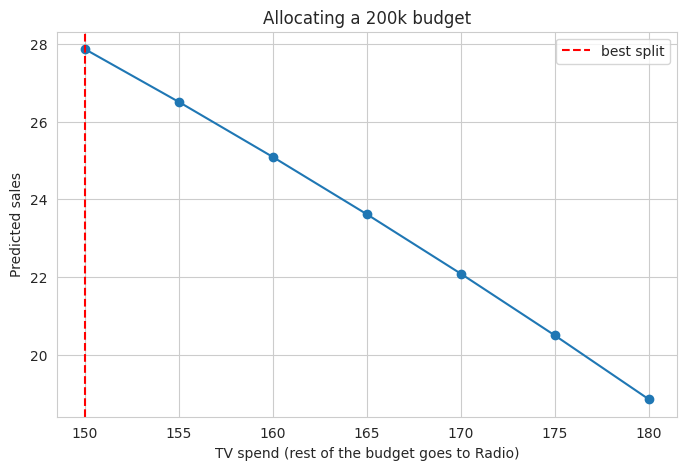

In [10]:
# Best split of a fixed total budget (Newspaper fixed at 0 because it adds little)
budget = 200
tv_grid = np.arange(60, 181, 5)
rows = []
for tv_spend in tv_grid:
    radio_spend = budget - tv_spend
    if 0 <= radio_spend <= 50:
        pred = best.predict(pd.DataFrame({"TV": [tv_spend], "Radio": [radio_spend], "Newspaper": [0]}))[0]
        rows.append((tv_spend, radio_spend, pred))
alloc = pd.DataFrame(rows, columns=["TV", "Radio", "Predicted_Sales"])
top = alloc.loc[alloc["Predicted_Sales"].idxmax()]
print(alloc.to_string(index=False))
print(f"\nBest split of a {budget}k budget: TV = {top.TV:.0f}k, Radio = {top.Radio:.0f}k -> predicted sales = {top.Predicted_Sales:.2f}")

plt.plot(alloc["TV"], alloc["Predicted_Sales"], marker="o")
plt.axvline(top.TV, color="r", linestyle="--", label="best split")
plt.xlabel("TV spend (rest of the budget goes to Radio)"); plt.ylabel("Predicted sales"); plt.title(f"Allocating a {budget}k budget"); plt.legend(); plt.show()

## Conclusion
TV and Radio are strong predictors of sales and Newspaper adds almost nothing. The TV x Radio synergy matters: the linear model *with* the interaction term scored best in cross-validation (R-squared about 0.98) versus about 0.94 for the plain linear model, with Random Forest and Gradient Boosting in between (about 0.96). Using the best model we forecast sales for several future budget scenarios, and the budget-allocation search puts Radio at the upper end of the range seen in the data (50k) with the rest on TV, because Radio generates more sales per dollar. Caveat: models are only reliable inside the range of budgets seen in training, so we cannot conclude that *even more* Radio would keep paying off.